# 08 · Individual Responses: Who Really Responded, and How Hard Did Each Person Work?

Notebooks 06 and 07 answered questions about **groups** ("stress raises HR by +5 bpm on average"). A physiotherapist or
coach makes decisions about **one person**. This notebook asks the questions a practitioner would ask:

1. **Did this person respond to the stress task, beyond their own measurement noise?**
2. **Do people genuinely differ in how they respond**, or is the spread just noise?
3. **Does each person respond through the same channel** (heart vs sweat glands)?
4. **How many repeated tests** would be needed to judge one person reliably?
5. **How hard did each person actually work** in the cycling protocol, relative to their own maximum, and can a wrist
   wearable tell you?

**Framework** (standard in sports science for individual decisions; Hopkins 2000; Atkinson & Batterham 2015;
Swinton et al. 2018):

| Term | Definition here |
|---|---|
| **Typical error (TE)** | How much one person's block mean changes between two comparable seated rests on the same day: SD(rest₁ − rest₂)/√2, pooled across participants |
| **Smallest worthwhile change (SWC)** | 0.2 × between-person SD at seated rest |
| **Individual response** | Stress task (TMCT) − seated baseline, the same contrast as notebook 06 |
| **90% interval** | response ± 1.645 × √2 × TE (both blocks carry measurement error) |
| **Clear response** | the whole interval lies above +SWC · **No meaningful response**: the whole interval lies below +SWC · **Unclear**: the interval contains +SWC |
| **True individual-response SD** | √(SD(responses)² − SD(rest₁ − rest₂)²): the spread left after removing measurement noise |

The categories describe **one session**, not a trait. The SWC of 0.2 SD is a convention from performance testing;
there is no established clinical threshold for stress reactivity.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.visualization import plots as P

P.set_style()
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
PROCESSED = ROOT / "data" / "processed"; INTERIM = ROOT / "data" / "interim"
C = P.COND_COLORS

from src.signals.quality import masked_features
from src.data.empatica import read_subject_info, read_stress_levels
from src.models import individual as I

w = pd.read_csv(PROCESSED / "windows.csv")
m = masked_features(w)
m["eda_log"] = np.log10(m.eda_tonic_mean.clip(lower=0.01))
prof, noise = I.build_profiles(m, read_subject_info(), read_stress_levels())
prof.to_csv(PROCESSED / "individual_profiles.csv")
noise.to_csv(PROCESSED / "individual_noise.csv")

CAT_COLORS = {I.RESPONSE: C["STRESS"], I.UNCLEAR: "#b9b7b0", I.NO_RESPONSE: P.TEXT_2}
print(prof.shape)

(36, 41)


## 1 · Measurement noise vs the smallest worthwhile change

Before judging anyone, establish how much a person's value moves **without any intervention**: between the second
halves of the two seated rests of the stress session (same day, same posture, same duration class).

In [2]:
cols = ["label", "n", "te", "te_low", "te_high", "swc", "mean_response", "repeats_needed", "te_conservative"]
noise[cols].round(3)

,label,n,te,te_low,te_high,swc,mean_response,repeats_needed,te_conservative
signal,,,,,,,,,
hr_mean,Heart rate (bpm),35,2.374,1.412,3.377,2.276,5.000,6,3.710
eda_log,EDA tonic (log10 µS),36,0.119,0.083,0.149,0.142,0.192,4,0.188
eda_scr_rate,SCR rate (per min),36,0.823,0.501,1.088,0.524,0.943,14,1.725


- **Heart rate:** typical error **2.4 bpm** (95% CI 1.4–3.4) against an SWC of **2.3 bpm**. The noise is as large as the
  smallest change worth detecting. That is the core difficulty of individual stress monitoring.
- **EDA level:** TE 0.12 log units (≈ ×1.3) against an SWC of 0.14 (≈ ×1.4).
- **SCR rate:** TE 0.8 per min against an SWC of 0.5 per min, so it is noisier than the threshold.
- A more conservative TE, from the baseline vs the first recovery, is larger (HR 3.7 bpm), because the baseline holds
  anticipatory arousal (notebook 06). The rest–rest estimate is used as the primary one; section 4 shows how the
  conclusions change with the conservative value.

## 2 · Do people genuinely respond differently?

If everyone had the same true response, the spread of observed responses would equal the spread of rest-to-rest
differences (pure noise). The excess is the **true individual-response SD**.

In [3]:
noise[["label", "mean_response", "sd_response", "sd_noise", "sd_ir", "sd_ir_low", "sd_ir_high"]].round(3)

,label,mean_response,sd_response,sd_noise,sd_ir,sd_ir_low,sd_ir_high
signal,,,,,,,
hr_mean,Heart rate (bpm),5.000,8.318,3.357,7.610,5.305,9.331
eda_log,EDA tonic (log10 µS),0.192,0.259,0.168,0.197,0.091,0.260
eda_scr_rate,SCR rate (per min),0.943,2.419,1.163,2.121,0.986,2.927


**Yes, clearly.** For heart rate the observed responses spread with SD 8.3 bpm, while noise alone accounts for 3.4 bpm.
The **true individual-response SD is 7.6 bpm (95% CI 5.3–9.3)** around a mean of +5.0 bpm. If true responses are
roughly normal, about one person in four has a true HR response at or below zero, and about one in four rises by more
than +10 bpm. The same holds for EDA level (true SD 0.20 log units, 0.09–0.26) and SCR rate (2.1 per min, 1.0–2.9).

So the group mean of notebook 06 is a real effect, but **it describes almost nobody**: people are spread far beyond
measurement noise. This is the statistical case for individual interpretation.

## 3 · Who responded? One row per person

Each row is one participant: response (dot) with its 90% interval (line). Dashed line = +SWC. Colour = category.

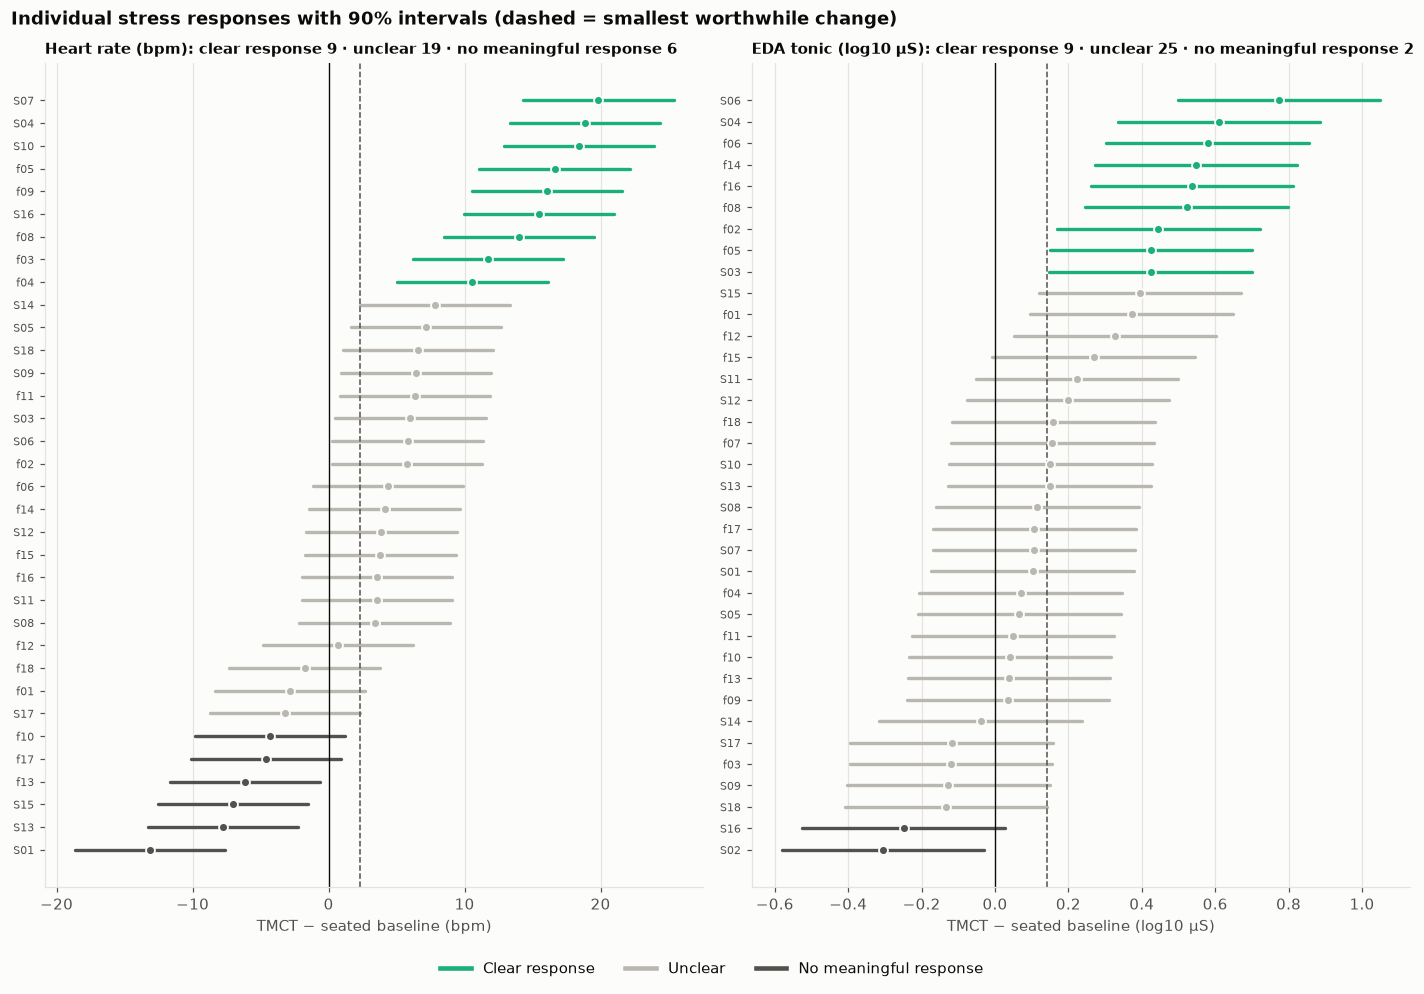

,hr_mean,eda_log,eda_scr_rate
Clear response,9,9,9
Unclear,19,25,23
No meaningful response,6,2,4


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 9))
for ax, f, unit in [(axes[0], "hr_mean", "bpm"), (axes[1], "eda_log", "log10 µS")]:
    d = prof[[f"{f}_response", f"{f}_ci90_low", f"{f}_ci90_high", f"{f}_category"]].dropna().sort_values(f"{f}_response")
    y = np.arange(len(d))
    for i, (sid, r) in enumerate(d.iterrows()):
        col = CAT_COLORS[r[f"{f}_category"]]
        ax.plot([r[f"{f}_ci90_low"], r[f"{f}_ci90_high"]], [i, i], color=col, lw=2.2, solid_capstyle="round")
        ax.scatter(r[f"{f}_response"], i, color=col, s=34, zorder=3, edgecolor=P.SURFACE, lw=1.2)
    ax.axvline(0, color=P.TEXT, lw=0.9)
    ax.axvline(noise.loc[f, "swc"], color=P.TEXT_2, lw=1, ls="--")
    ax.set_yticks(y, d.index, fontsize=7.5); ax.grid(axis="y", visible=False)
    ax.set_xlabel(f"TMCT − seated baseline ({unit})")
    counts = d[f"{f}_category"].value_counts()
    ax.set_title(f"{I.SIGNALS[f]}: " + " · ".join(f"{k.lower()} {counts.get(k, 0)}" for k in I.CATEGORIES), loc="left", fontsize=10)
handles = [plt.Line2D([], [], color=c, lw=3, label=k) for k, c in CAT_COLORS.items()]
fig.legend(handles=handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Individual stress responses with 90% intervals (dashed = smallest worthwhile change)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0.03, 1, 1)); P.save(fig, "08_individual_responses"); plt.show()
pd.DataFrame({f: prof[f"{f}_category"].value_counts() for f in I.SIGNALS}).reindex(I.CATEGORIES)

With one 3–4.5-minute stress task:
- **Heart rate:** 9 of 34 participants show a clear response, 6 show no meaningful response and **19 are unclear**.
- **EDA level:** 9 clear, 2 no meaningful response, **25 unclear**.
- **SCR rate:** 9 clear, 4 none, 23 unclear.

The true differences between people are large (section 2), but **a single short test can resolve them for only about
one person in four**. The limiting factor is the measurement, not the analysis.

## 4 · How many repeated tests would a practitioner need?

If a person repeated the test k times and the responses were averaged, the 90% interval half-width would shrink to
1.645 × √2 × TE / √k. The curve below shows when that half-width falls below the SWC, i.e. when a response of
twice the SWC could be classified as clear with confidence.

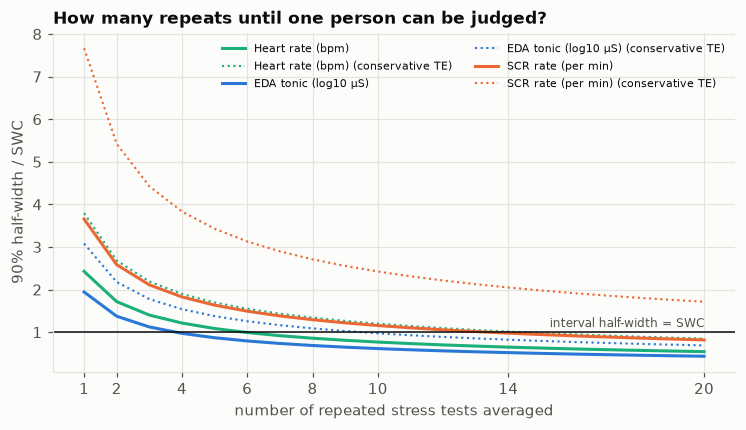

,label,repeats_needed,conservative: Clear response,conservative: Unclear,conservative: No meaningful response
signal,,,,,
hr_mean,Heart rate (bpm),6,8,23,3
eda_log,EDA tonic (log10 µS),4,3,32,1
eda_scr_rate,SCR rate (per min),14,3,32,1


In [5]:
k = np.arange(1, 21)
fig, ax = plt.subplots(figsize=(8, 4))
for f, col in zip(I.SIGNALS, [C["STRESS"], C["AEROBIC"], C["ANAEROBIC"]]):
    for te_col, ls, lab in [("te", "-", ""), ("te_conservative", ":", " (conservative TE)")]:
        half = I.Z90 * np.sqrt(2) * noise.loc[f, te_col] / np.sqrt(k) / noise.loc[f, "swc"]
        ax.plot(k, half, color=col, ls=ls, lw=2 if ls == "-" else 1.4, label=I.SIGNALS[f] + lab)
ax.axhline(1, color=P.TEXT, lw=1)
ax.text(20, 1.05, "interval half-width = SWC", ha="right", va="bottom", fontsize=8, color=P.TEXT_2)
ax.set_xlabel("number of repeated stress tests averaged"); ax.set_ylabel("90% half-width / SWC")
ax.set_xticks([1, 2, 4, 6, 8, 10, 14, 20]); ax.legend(fontsize=7.5, ncol=2)
ax.set_title("How many repeats until one person can be judged?", loc="left")
P.save(fig, "08_repeats_needed"); plt.show()

cons = {}
for f in I.SIGNALS:
    x = prof[f"{f}_response"].dropna()
    cons[f] = I.classify(x.to_numpy(), noise.loc[f, "te_conservative"], noise.loc[f, "swc"]).category.value_counts()
sens = pd.DataFrame(cons).reindex(I.CATEGORIES)
noise[["label", "repeats_needed"]].join(sens.T.add_prefix("conservative: "))

- **Heart rate needs about 6 repeated tests**, EDA level about 4, and SCR rate about 14, before the measurement noise is
  smaller than the smallest worthwhile change. With the conservative TE they rise to about 15, 10 and 60.
- With the conservative TE, fewer people are classified as clear responders (HR 8, EDA 3, SCR 3), but the main
  conclusion does not change: **one session is not enough to label an individual**.
- **Practical translation:** to know whether a client is a "high stress reactor", measure them on several days, or
  use longer and repeated stress exposures, and compare against their own baseline, never a population threshold.

## 5 · Same stressor, different channels

Each point is a person: HR response vs EDA response. Dashed lines are the SWCs.

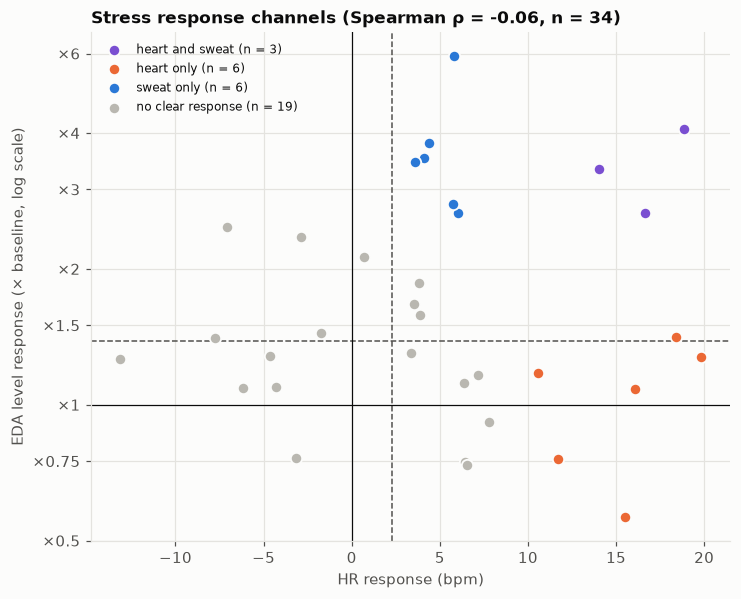

eda_log_category        Clear response  No meaningful response  Unclear
hr_mean_category                                                       
Clear response                       3                       1        5
No meaningful response               0                       0        6
Unclear                              6                       0       13


,selfreport_change,movement_change,count
profile,,,
heart and sweat,1.000,-0.001,3
heart only,2.000,0.001,6
no clear response,2.000,-0.006,19
sweat only,2.500,-0.007,6


In [6]:
PCOL = {"heart and sweat": "#7a4fd1", "heart only": C["ANAEROBIC"], "sweat only": C["AEROBIC"], "no clear response": "#b9b7b0"}
fig, ax = plt.subplots(figsize=(7.5, 6))
for p, col in PCOL.items():
    d = prof[prof.profile == p]
    ax.scatter(d.hr_mean_response, d.eda_ratio, color=col, s=55, edgecolor=P.SURFACE, lw=1.2, label=f"{p} (n = {len(d)})", zorder=3)
ax.set_yscale("log")
ax.set_yticks([0.5, 0.75, 1, 1.5, 2, 3, 4, 6], ["×0.5", "×0.75", "×1", "×1.5", "×2", "×3", "×4", "×6"]); ax.minorticks_off()
ax.axvline(noise.loc["hr_mean", "swc"], color=P.TEXT_2, ls="--", lw=1); ax.axhline(10 ** noise.loc["eda_log", "swc"], color=P.TEXT_2, ls="--", lw=1)
ax.axvline(0, color=P.TEXT, lw=0.8); ax.axhline(1, color=P.TEXT, lw=0.8)
ax.set_xlabel("HR response (bpm)"); ax.set_ylabel("EDA level response (× baseline, log scale)")
from scipy import stats
d = prof[["hr_mean_response", "eda_log_response"]].dropna()
rho = stats.spearmanr(d.hr_mean_response, d.eda_log_response)
ax.set_title(f"Stress response channels (Spearman ρ = {rho.statistic:.2f}, n = {len(d)})", loc="left")
ax.legend(fontsize=8, loc="upper left")
P.save(fig, "08_response_profiles"); plt.show()
print(pd.crosstab(prof.hr_mean_category, prof.eda_log_category))
prof.groupby("profile")[["selfreport_change", "movement_change"]].median().round(3).join(prof.profile.value_counts())

- HR and EDA responses are **unrelated across people** (ρ ≈ −0.06). Among the 15 people with a clear response on at
  least one signal, **only 3 respond on both**. Six respond only through the heart, six only through the sweat glands.
  **Monitoring a single channel would miss about half of the clear responders.**
- **Self-reported stress** changes by a similar amount in all profiles (median +1 to +2.5 points). How stressed someone
  *says* they are does not tell you which physiological channel will respond, or whether any will. S04 (card below)
  responds clearly on both channels while reporting no change at all.
- **Movement** fell during the task for 26 of 36 participants, in every profile. These responses are not movement
  artefacts.

## 6 · Relative exercise intensity: how hard did each person actually work?

The aerobic protocol prescribes **cadences**, not intensities. To compare people, express heart rate relative to each
person's **age-predicted maximum** (Tanaka et al. 2001: 208 − 0.7 × age) and classify it with the ACSM categories
(Garber et al. 2011): light 57–63%, moderate 64–76%, vigorous 77–95%, near-maximal ≥ 96% HRmax.

Two reliability flags, used only to *label* data, never to exclude them:
- **enough data:** at least 3 quality-valid 30-s windows in the final stage;
- **peak ≥ moderate:** HR in the final stage is not lower than in the moderate stages. In an incremental test it should
  not be, so a lower value points to a measurement problem (a physiological sensitivity check, as in notebook 02).

aerobic participants with age: 30 | with any valid peak HR: 22 | enough data: 16 | reliable: 14


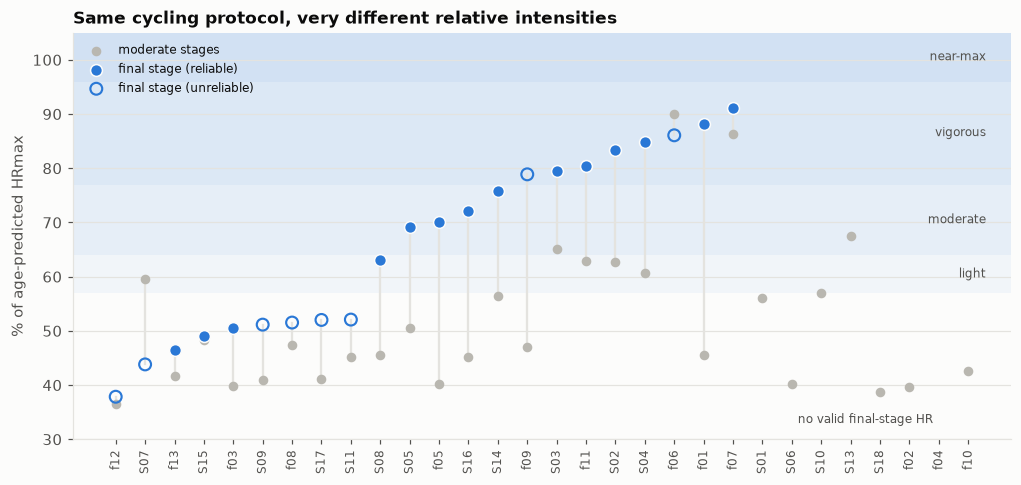

,sex,age,active,peak_stage,hr_peak,pct_hrmax_peak,acsm_peak,peak_valid_windows
subject_id,,,,,,,,
f13,f,29.000,No,rpm_90_95,87.100,46.400,very light,4
S15,m,21.000,Yes,rpm_110,94.700,49.000,very light,4
f03,f,26.000,Yes,rpm_90_95,95.700,50.400,very light,3
S08,m,20.000,Yes,rpm_110,122.300,63.000,light,5
S05,m,21.000,Yes,rpm_110,133.700,69.200,moderate,5
f05,f,21.000,Yes,rpm_85,135.600,70.200,moderate,5
S16,m,20.000,Yes,rpm_110,140.000,72.200,moderate,7
S14,m,19.000,Yes,rpm_110,147.500,75.800,moderate,3
S03,m,20.000,Yes,rpm_85,154.200,79.500,vigorous,9


In [7]:
ex = prof[prof.hr_valid_aerobic.notna()].copy()
ex = ex[ex.age.notna()]
print("aerobic participants with age:", len(ex), "| with any valid peak HR:", ex.pct_hrmax_peak.notna().sum(),
      "| enough data:", (ex.peak_enough_data & ex.pct_hrmax_peak.notna()).sum(), "| reliable:", ex.peak_reliable.sum())
d = ex.sort_values("pct_hrmax_peak")
fig, ax = plt.subplots(figsize=(11, 4.8))
bands = [(57, 64, "light"), (64, 77, "moderate"), (77, 96, "vigorous"), (96, 105, "near-max")]
for lo, hi, lab in bands:
    ax.axhspan(lo, hi, color=C["AEROBIC"], alpha=0.05 + 0.05 * bands.index((lo, hi, lab)), lw=0)
    ax.text(len(d) - 0.4, (lo + hi) / 2, lab, fontsize=8, color=P.TEXT_2, va="center", ha="right")
x = np.arange(len(d))
ax.scatter(x, d.pct_hrmax_moderate, color="#b9b7b0", s=28, label="moderate stages", zorder=3)
rel = d.peak_reliable.to_numpy()
ax.scatter(x[rel], d.pct_hrmax_peak[rel], color=C["AEROBIC"], s=60, label="final stage (reliable)", zorder=4, edgecolor=P.SURFACE)
ax.scatter(x[~rel], d.pct_hrmax_peak[~rel], facecolor="none", edgecolor=C["AEROBIC"], s=60, lw=1.4, label="final stage (unreliable)", zorder=4)
for i, (sid, r) in enumerate(d.iterrows()):
    if np.isfinite(r.pct_hrmax_moderate) and np.isfinite(r.pct_hrmax_peak):
        ax.plot([i, i], [r.pct_hrmax_moderate, r.pct_hrmax_peak], color=P.GRID, lw=1.5, zorder=2)
ax.set_xticks(x, d.index, rotation=90, fontsize=8); ax.set_ylim(30, 105)
n_none = int(d.pct_hrmax_peak.isna().sum())
if n_none:
    ax.text(len(d) - n_none / 2 - 0.5, 33, "no valid final-stage HR", ha="center", fontsize=8, color=P.TEXT_2)
ax.set_ylabel("% of age-predicted HRmax"); ax.grid(axis="x", visible=False)
ax.legend(fontsize=8, loc="upper left")
ax.set_title("Same cycling protocol, very different relative intensities", loc="left")
P.save(fig, "08_relative_intensity"); plt.show()
ex.loc[ex.peak_reliable, ["sex", "age", "active", "peak_stage", "hr_peak", "pct_hrmax_peak", "acsm_peak", "peak_valid_windows"]].sort_values("pct_hrmax_peak").round(1)

- **Only 14 of the 30 aerobic participants have a final-stage heart rate a practitioner could use** (enough valid data
  and not lower than the moderate stages). For the other 16, the wrist PPG either failed or produced values that
  cannot be right for the hardest stage of an incremental test. Some of these "valid" values sit close to the pedalling
  rhythm, but at this level a cadence match also happens by chance, so it cannot be proven case by case.
- Among the 14 reliable participants, the **same protocol ended anywhere from 46% to 91% of predicted HRmax** (median
  74%): from *very light* to *vigorous*. A cadence-based protocol does **not** produce the same relative intensity in
  everyone. This matters for any study, or any training plan, that prescribes exercise by external load alone.
- **Moderate stages were very light for most people** (median ≈ 47% HRmax): the 70–85 rpm stages were a warm-up in
  physiological terms.
- **Caveats.** Age-predicted HRmax has an individual error of roughly ±10 bpm (≈ ±5 percentage points). Load, resistance
  and fitness are not recorded. Regular activity is confounded with cohort and sex (V1 men mostly active, V2 women mostly
  not), so no comparison by training status is made.

## 7 · Profile cards

Three participants, chosen automatically as the clearest example of each response profile, summarised the way a
practitioner would want to see them. The full table for all 36 participants is
`data/processed/individual_profiles.csv`, and the project site has an interactive card for every participant.

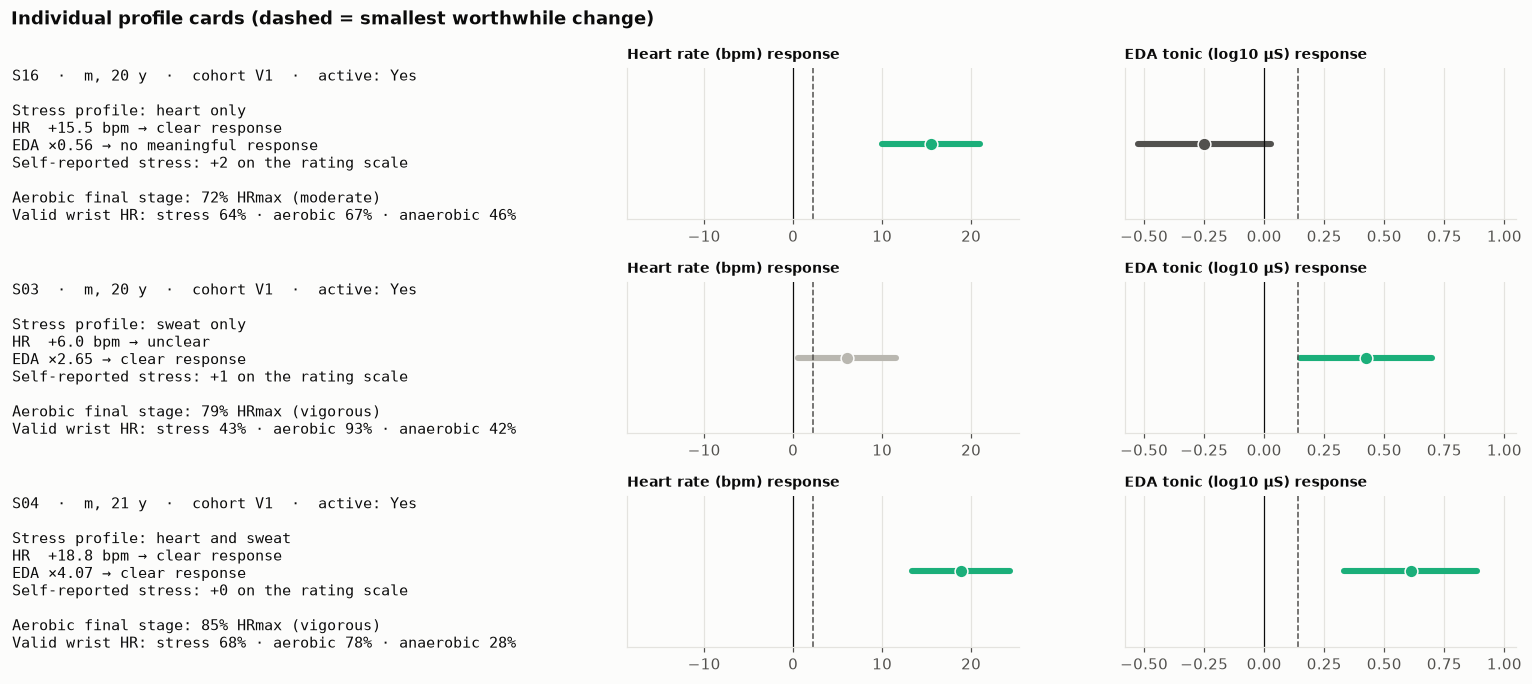

['S16', 'S03', 'S04']

In [8]:
def pick(profile):
    d = prof[prof.profile == profile].copy()
    d["score"] = d.hr_mean_response.abs() / noise.loc["hr_mean", "swc"] + d.eda_log_response.abs() / noise.loc["eda_log", "swc"] + 3 * d.peak_reliable
    return d.score.idxmax() if len(d) else None
examples = [s for s in (pick("heart only"), pick("sweat only"), pick("heart and sweat")) if s]

def verdict(cat):
    return {I.RESPONSE: "clear response", I.UNCLEAR: "unclear", I.NO_RESPONSE: "no meaningful response"}.get(cat, "no data")

fig, axes = plt.subplots(len(examples), 3, figsize=(14, 2.1 * len(examples)), gridspec_kw={"width_ratios": [1.3, 1, 1]})
for row, sid in zip(np.atleast_2d(axes), examples):
    r = prof.loc[sid]
    a0, a1, a2 = row
    a0.axis("off")
    age = "?" if not np.isfinite(r.age) else int(r.age)
    lines = [f"{sid}  ·  {r.sex}, {age} y  ·  cohort {r.cohort}  ·  active: {r.active if isinstance(r.active, str) else '?'}",
             "",
             f"Stress profile: {r.profile}",
             f"HR  {r.hr_mean_response:+.1f} bpm → {verdict(r.hr_mean_category)}",
             f"EDA ×{r.eda_ratio:.2f} → {verdict(r.eda_log_category)}",
             f"Self-reported stress: {r.selfreport_change:+.0f} on the rating scale",
             "",
             f"Aerobic final stage: " + (f"{r.pct_hrmax_peak:.0f}% HRmax ({r.acsm_peak})" if r.peak_reliable else "not reliably measured"),
             f"Valid wrist HR: stress {r.hr_valid_stress:.0%} · aerobic {r.hr_valid_aerobic:.0%} · anaerobic {r.hr_valid_anaerobic:.0%}"]
    a0.text(0, 1, "\n".join(lines), va="top", fontsize=9.5, family="monospace", transform=a0.transAxes)
    for ax, f in [(a1, "hr_mean"), (a2, "eda_log")]:
        resp, lo, hi, cat = r[f"{f}_response"], r[f"{f}_ci90_low"], r[f"{f}_ci90_high"], r[f"{f}_category"]
        col = CAT_COLORS.get(cat, "#b9b7b0")
        ax.plot([lo, hi], [0, 0], color=col, lw=4, solid_capstyle="round"); ax.scatter(resp, 0, color=col, s=70, zorder=3, edgecolor=P.SURFACE)
        ax.axvline(0, color=P.TEXT, lw=0.8); ax.axvline(noise.loc[f, "swc"], color=P.TEXT_2, ls="--", lw=1)
        all_lo, all_hi = prof[f"{f}_ci90_low"].min(), prof[f"{f}_ci90_high"].max()
        ax.set_xlim(all_lo, all_hi); ax.set_ylim(-1, 1); ax.set_yticks([]); ax.grid(axis="y", visible=False)
        ax.set_title(I.SIGNALS[f] + " response", loc="left", fontsize=9)
fig.suptitle("Individual profile cards (dashed = smallest worthwhile change)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); P.save(fig, "08_profile_cards"); plt.show()
examples

## Take-home for practitioners

1. **The average response describes almost nobody.** True individual differences in the stress response are large
   (HR: SD 7.6 bpm around a mean of +5 bpm).
2. **One short test cannot label a person.** Measurement noise is about the size of the smallest worthwhile change.
   About 1 in 4 people can be classified clearly; about 6 repeated tests would be needed for heart rate.
3. **People respond through different channels.** Heart and sweat responses are unrelated. Monitoring one signal
   misses about half of the clear responders, and self-report does not predict which channel will respond.
4. **External load ≠ internal load.** The same cadence protocol produced 46–91% of predicted HRmax in the people who
   could be measured. Prescribe and verify intensity individually.
5. **Check whether the wearable can measure the person before interpreting them.** During cycling, wrist HR was
   usable at the final stage in fewer than half of the participants.

The practitioner guide (`docs/practitioner_guide.md`, Spanish version `docs/guia_profesional.md`) turns these points
into a one-page decision table.